In [33]:
import pandas as pd
df = pd.read_csv('../data/clean_sales.csv', parse_dates=['InvoiceDate'])
df_return = pd.read_csv('../data/returns.csv', parse_dates=['InvoiceDate'])

In [34]:
df.shape

(1003404, 9)

In [35]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [36]:
df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(5).round(0)

Country
United Kingdom    16562935.0
EIRE                625038.0
Netherlands         549773.0
Germany             383419.0
France              311147.0
Name: Revenue, dtype: float64

In [37]:
df['month'] = df['InvoiceDate'].dt.month
df.groupby('month')['Revenue'].sum().round(0)


month
1     1214482.0
2     1045710.0
3     1451539.0
4     1161741.0
5     1383445.0
6     1434873.0
7     1321214.0
8     1398254.0
9     1897564.0
10    2197750.0
11    2881817.0
12    2019674.0
Name: Revenue, dtype: float64

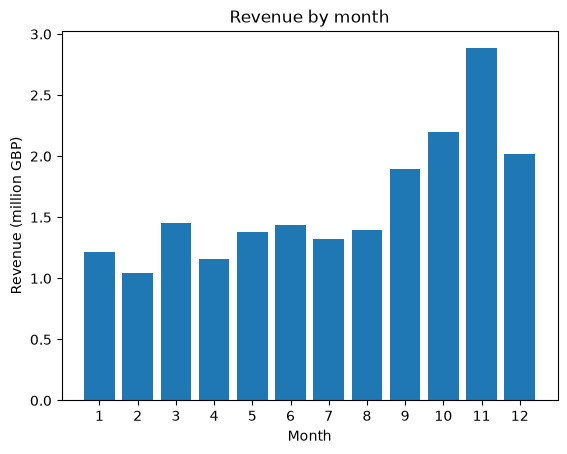

In [38]:
import matplotlib.pyplot as plt
df['month'] = df['InvoiceDate'].dt.month
monthly = df.groupby('month')['Revenue'].sum().round(0)
plt.bar(monthly.index, monthly.values / 1000000)
plt.title('Revenue by month')
plt.xlabel('Month')
plt.ylabel('Revenue (million GBP)')
plt.xticks(range(1, 13))
plt.savefig('../images/revenue_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

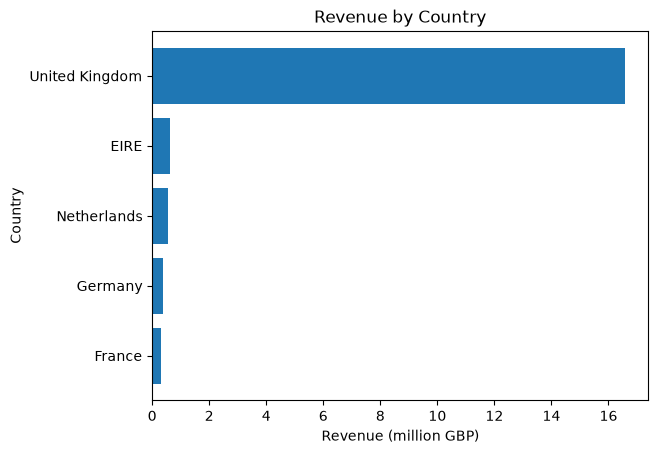

In [39]:
import matplotlib.pyplot as plt
countries = df.groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5)
plt.barh(countries.index, countries.values/1000000)
plt.title('Revenue by Country')
plt.xlabel('Revenue (million GBP)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.savefig('../images/revenue_by_country.png', dpi=150, bbox_inches='tight')
plt.show()


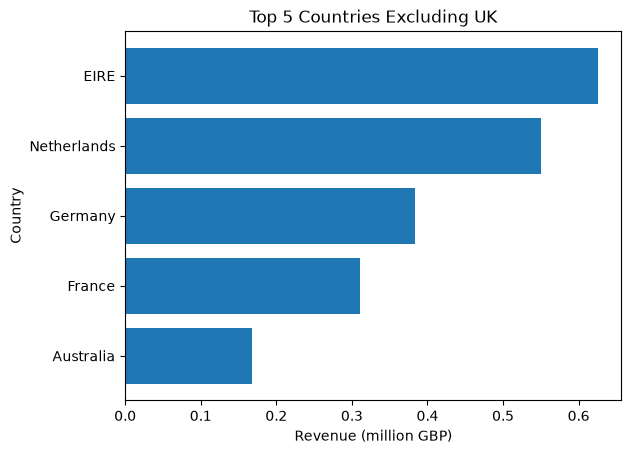

In [40]:
import matplotlib.pyplot as plt
#df = df[df['Country'] != 'United Kingdom']
df_intl = df[df['Country'] != 'United Kingdom'].groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5)
plt.barh(df_intl.index, df_intl.values/1000000)
plt.title('Top 5 Countries Excluding UK')
plt.xlabel('Revenue (million GBP)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.savefig('../images/top_international_countries.png', dpi=150, bbox_inches='tight')
plt.show()

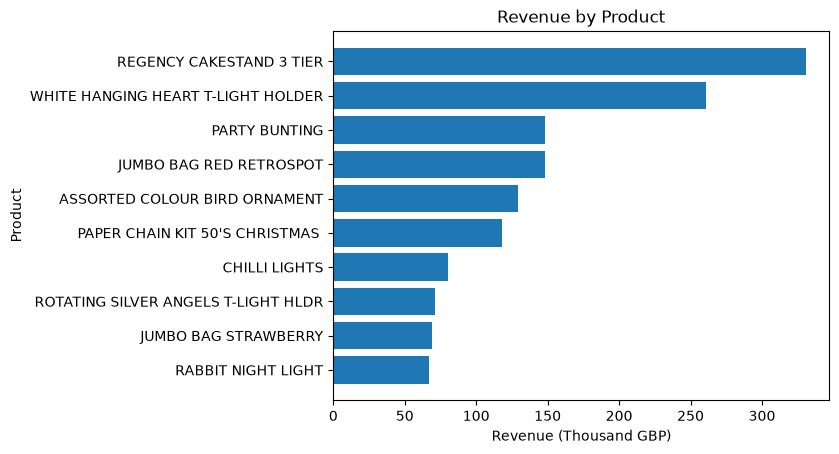

In [41]:
import matplotlib.pyplot as plt
not_products = df['Description'].isin(['Manual', 'DOTCOM POSTAGE', 'POSTAGE'])
df_products = df[~not_products]
products = df_products.groupby('Description')['Revenue'].sum().round(0).sort_values(ascending=False).head(10)
plt.barh(products.index, products.values/1000)
plt.title('Revenue by Product')
plt.xlabel('Revenue (Thousand GBP)')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.savefig('../images/revenue_by_product.png', dpi=150, bbox_inches='tight')
plt.show()

In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1003404 entries, 0 to 1003403
Data columns (total 10 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1003404 non-null  int64         
 1   StockCode    1003404 non-null  str           
 2   Description  1003404 non-null  str           
 3   Quantity     1003404 non-null  int64         
 4   InvoiceDate  1003404 non-null  datetime64[us]
 5   Price        1003404 non-null  float64       
 6   Customer ID  776639 non-null   float64       
 7   Country      1003404 non-null  str           
 8   Revenue      1003404 non-null  float64       
 9   month        1003404 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(1), int64(2), str(3)
memory usage: 72.7 MB


In [43]:
df['Customer ID'].nunique()

5861

In [44]:
df['Invoice'].nunique()

39563

In [45]:
df.shape

(1003404, 10)

In [46]:
df.sort_values('Quantity', ascending=False).head(3)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,month
86780,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.1,13902.0,Denmark,1915.2,2
121395,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.1,13902.0,Denmark,1296.0,3
121393,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.1,13902.0,Denmark,1296.0,3


In [47]:
df['StockCode'].str.len().value_counts()

StockCode
5    882043
6    119997
7      1223
8        99
9        25
4        17
Name: count, dtype: int64

In [48]:
df[df['StockCode'].str.len() < 5][['StockCode', 'Description']].drop_duplicates()

,StockCode,Description
59785,PADS,PADS TO MATCH ALL CUSHIONS


In [49]:
top_returns = df_return.groupby('Description')['Quantity'].sum().sort_values().head(10)
top_returns

Description
ROTATING SILVER ANGELS T-LIGHT HLDR   -9381
SET/6 FRUIT SALAD PAPER CUPS          -7140
SET/6 FRUIT SALAD  PAPER PLATES       -7008
POP ART PEN CASE & PENS               -5184
BLACK SILVER FLOWER T-LIGHT HOLDER    -5040
MULTICOLOUR SPRING FLOWER MUG         -4996
TEATIME PEN CASE & PENS               -4632
WHITE BIRD GARDEN DESIGN MUG          -4320
S/4 BLUE ROUND DECOUPAGE BOXES        -3940
THE KING GIFT BAG                     -3744
Name: Quantity, dtype: int64

In [50]:
df_return.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


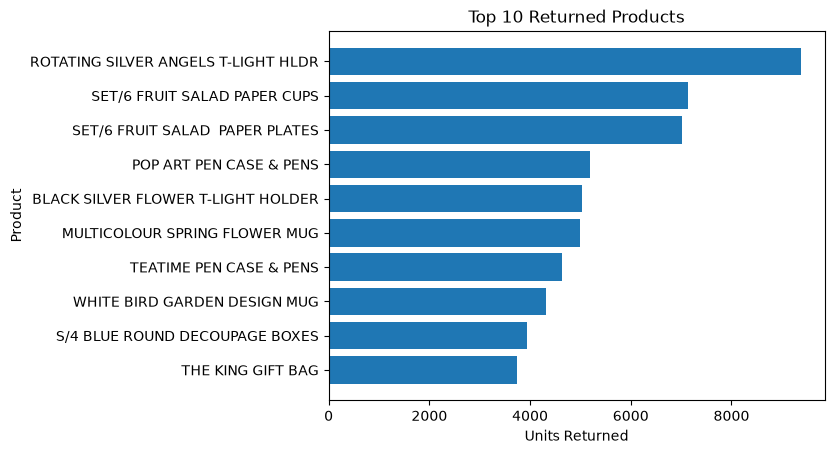

In [51]:
import matplotlib.pyplot as plt
#top_products = -(top_returns.groupby('Description')['Quantity'].sum().round(0).sort_values(ascending=False).head(10))
plt.barh(top_returns.index, -top_returns.values)
plt.title('Top 10 Returned Products')
plt.xlabel('Units Returned')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.savefig('../images/top_returns.png', dpi=150, bbox_inches='tight')
plt.show()

In [52]:
units_returned = -df_return['Quantity'].sum()
units_sold = df['Quantity'].sum()
units_returned / units_sold

np.float64(0.028331702308568494)

In [53]:
df_return[df_return['Description'] == 'ROTATING SILVER ANGELS T-LIGHT HLDR'].sort_values('Quantity').head(3)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
9314,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.0,United Kingdom
9391,C537251,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9,2010-12-06 10:45:00,2.55,NaN,United Kingdom
10009,C540164,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-6,2011-01-05 12:02:00,2.55,14911.0,EIRE


In [54]:
returns_count = df_return.groupby('Description')['Quantity'].count().sort_values(ascending=False).head(10)
returns_count

Description
REGENCY CAKESTAND 3 TIER              341
BAKING SET 9 PIECE RETROSPOT          209
STRAWBERRY CERAMIC TRINKET BOX        181
WHITE HANGING HEART T-LIGHT HOLDER    134
WHITE CHERRY LIGHTS                   121
RED RETROSPOT CAKE STAND              107
JAM MAKING SET WITH JARS               87
PINK CHERRY LIGHTS                     86
WOOD 2 DRAWER CABINET WHITE FINISH     85
SET OF 3 CAKE TINS PANTRY DESIGN       73
Name: Quantity, dtype: int64

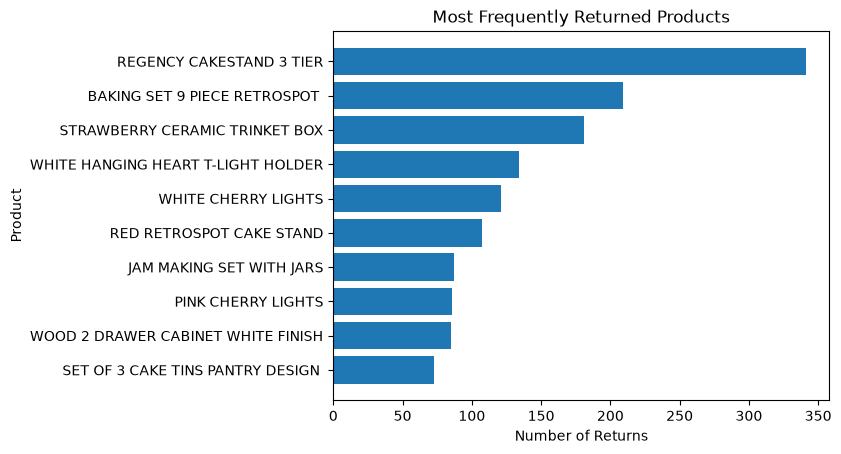

In [55]:
plt.barh(returns_count.index, returns_count.values)
plt.title('Most Frequently Returned Products')
plt.xlabel('Number of Returns')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.savefig('../images/most_returned_products.png', dpi=150, bbox_inches='tight')
plt.show()

In [56]:
df_return[df_return['Description'].str.contains('FRUIT SALAD', na=False)].sort_values('Quantity').head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
7044,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,2010-09-28 11:02:00,0.08,14277.0,France
7045,C524235,21096,SET/6 FRUIT SALAD PAPER PLATES,-7008,2010-09-28 11:02:00,0.13,14277.0,France
7043,C524235,21082,SET/20 FRUIT SALAD PAPER NAPKINS,-3072,2010-09-28 11:02:00,0.17,14277.0,France
12500,C553533,21088,SET/6 FRUIT SALAD PAPER CUPS,-12,2011-05-17 15:13:00,0.19,17612.0,United Kingdom
1420,C495319,21082,SET/20 FRUIT SALAD PAPER NAPKINS,-2,2010-01-22 15:09:00,0.85,17888.0,United Kingdom


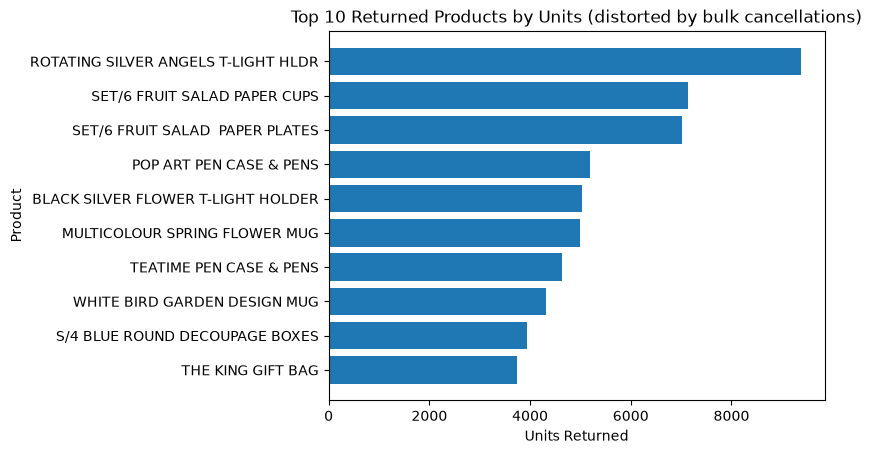

In [57]:
plt.barh(top_returns.index, -top_returns.values)
plt.title('Top 10 Returned Products by Units (distorted by bulk cancellations)')
plt.xlabel('Units Returned')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.savefig('../images/top_returns_units.png', dpi=150, bbox_inches='tight')
plt.show()

In [58]:
print(df.shape)
print(df['InvoiceDate'].min(), df['InvoiceDate'].max())
print(df['Revenue'].sum().round(0))
print(df['Customer ID'].nunique(), df['Invoice'].nunique())
print(df.groupby('Country')['Revenue'].sum().round(0).sort_values(ascending=False).head(5))
print(df.groupby(df['InvoiceDate'].dt.month)['Revenue'].sum().round(0))
print(df.groupby('Description')['Revenue'].sum().round(0).sort_values(ascending=False).head(5))

(1003404, 10)
2009-12-01 07:45:00 2011-12-09 12:50:00
19408063.0
5861 39563
Country
United Kingdom    16562935.0
EIRE                625038.0
Netherlands         549773.0
Germany             383419.0
France              311147.0
Name: Revenue, dtype: float64
InvoiceDate
1     1214482.0
2     1045710.0
3     1451539.0
4     1161741.0
5     1383445.0
6     1434873.0
7     1321214.0
8     1398254.0
9     1897564.0
10    2197750.0
11    2881817.0
12    2019674.0
Name: Revenue, dtype: float64
Description
REGENCY CAKESTAND 3 TIER              330590.0
WHITE HANGING HEART T-LIGHT HOLDER    260990.0
PARTY BUNTING                         148318.0
JUMBO BAG RED RETROSPOT               148073.0
ASSORTED COLOUR BIRD ORNAMENT         129324.0
Name: Revenue, dtype: float64
